# 📊 Análise Gráfica de Produtos de E-commerce

**Objetivo:** criar gráficos a partir do arquivo `ecommerce_estatistica.csv` para extrair valor para o cliente, entendendo melhor preços, avaliações, descontos e vendas dos produtos.

**Os 7 gráficos deste notebook**

| # | Gráfico | Pergunta que ele responde |
|---|---------|---------------------------|
| 1 | Histograma | Como os preços estão distribuídos? |
| 2 | Dispersão | Produtos mais caros têm descontos maiores? |
| 3 | Mapa de calor | Quais variáveis numéricas andam juntas? |
| 4 | Barra | Quais marcas mais aparecem no catálogo? |
| 5 | Pizza | Como o catálogo se divide por gênero? |
| 6 | Densidade | O preço muda entre produtos masculinos e femininos? |
| 7 | Regressão | Mais avaliações significam mais vendas? |

## 1. Importando as bibliotecas

- **pandas**: lê e manipula tabelas (DataFrames).
- **numpy**: faz contas numéricas.
- **matplotlib** e **seaborn**: criam os gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Deixa os gráficos com um visual mais limpo e tamanho padrão maior
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## 2. Lendo o arquivo CSV

Usamos `pd.read_csv` para carregar os dados em um DataFrame chamado `df`.
O arquivo deve estar **na mesma pasta** do notebook.

In [2]:
df = pd.read_csv("ecommerce_estatistica.csv")
df.head()

,Unnamed: 0,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,...,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,1,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,...,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
1,2,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,...,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
2,3,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...",...,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
3,4,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,...,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466
4,5,Blusa + Calça Térmica Treino Futebol Criança I...,4.7,58.0,5.0,roupa zero grau,termico unissex,Sem gênero infantil,outono/inverno,"Produto ótimo , mesmo após várias lavagens não...",...,0.888889,0.006280,0.000000,0.114508,669,166,3,100.0,0.002274,0.000910


## 3. Conhecendo os dados

In [3]:
# Quantas linhas e colunas?
print("Linhas e colunas:", df.shape)

# Tipos de dados e valores nulos
df.info()

Linhas e colunas: (295, 24)
<class 'pandas.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           295 non-null    int64  
 1   Título               295 non-null    str    
 2   Nota                 295 non-null    float64
 3   N_Avaliações         295 non-null    float64
 4   Desconto             295 non-null    float64
 5   Marca                295 non-null    str    
 6   Material             295 non-null    str    
 7   Gênero               295 non-null    str    
 8   Temporada            295 non-null    str    
 9   Review1              295 non-null    str    
 10  Review2              295 non-null    str    
 11  Review3              295 non-null    str    
 12  Qtd_Vendidos         295 non-null    str    
 13  Preço                295 non-null    float64
 14  Nota_MinMax          295 non-null    float64
 15  N_Avaliações_MinMax  29

In [4]:
# Resumo estatístico das colunas numéricas que vamos usar
colunas_principais = ["Nota", "N_Avaliações", "Desconto", "Preço", "Qtd_Vendidos_Cod"]
df[colunas_principais].describe().round(2)

,Nota,N_Avaliações,Desconto,Preço,Qtd_Vendidos_Cod
count,295.00,295.00,295.00,295.00,295.00
mean,4.48,490.51,16.01,130.84,2946.31
std,0.32,1079.40,9.93,64.23,8068.02
min,2.30,3.00,5.00,25.63,5.00
25%,4.30,19.00,9.00,73.34,100.00
50%,4.50,77.00,11.00,129.21,100.00
75%,4.70,326.00,22.00,179.90,1000.00
max,5.00,9077.00,51.00,326.55,50000.00


In [5]:
# Há valores faltando? (0 em todas as colunas = dados completos)
df.isnull().sum().sum()

np.int64(0)

### O que as colunas significam

| Coluna | Significado |
|--------|-------------|
| `Nota` | Nota média do produto (0 a 5) |
| `N_Avaliações` | Quantidade de avaliações recebidas |
| `Desconto` | Percentual de desconto (%) |
| `Preço` | Preço do produto (R$) |
| `Qtd_Vendidos_Cod` | Quantidade vendida convertida para número (ex.: "+10mil" vira 10000) |
| `Marca`, `Gênero`, `Temporada` | Categorias do produto |

> As colunas terminadas em `_MinMax`, `_Cod` e `_Freq` são versões transformadas das originais (normalizadas ou codificadas) criadas nos exercícios anteriores. Aqui usamos principalmente as colunas originais, que são mais fáceis de interpretar.

## 4. Histograma — distribuição dos preços

O histograma divide os preços em faixas (as "barras") e conta quantos produtos caem em cada uma.
A linha tracejada vermelha mostra a **média** e a verde a **mediana**.

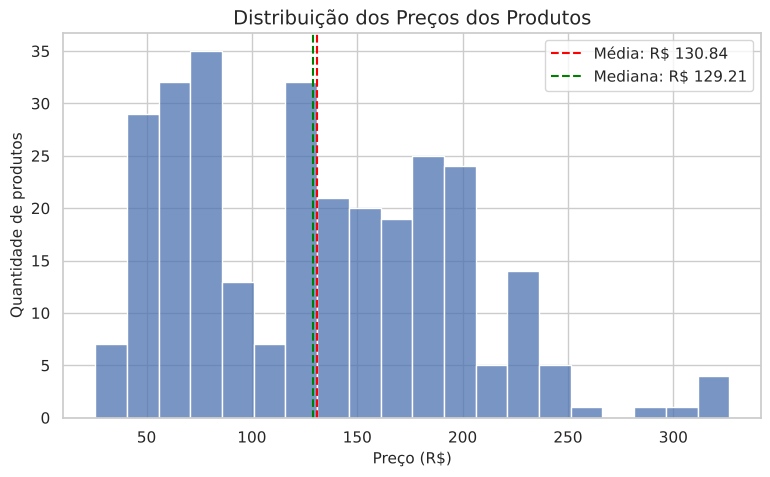

In [6]:
plt.figure()
sns.histplot(data=df, x="Preço", bins=20, color="#4C72B0")

plt.axvline(df["Preço"].mean(), color="red", linestyle="--", label=f"Média: R$ {df['Preço'].mean():.2f}")
plt.axvline(df["Preço"].median(), color="green", linestyle="--", label=f"Mediana: R$ {df['Preço'].median():.2f}")

plt.title("Distribuição dos Preços dos Produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Quantidade de produtos")
plt.legend()
plt.show()

**Leitura:** a maior parte dos produtos custa entre cerca de R$ 50 e R$ 200, e poucos passam de R$ 250. Note que há **dois grupos de preço**: um pico em torno de R$ 50–80 e outro perto de R$ 130, o que sugere tipos de produto diferentes (peças baratas e peças intermediárias). Média e mediana são próximas.

## 5. Gráfico de dispersão — preço × desconto

Cada ponto é **um produto**. A posição mostra o preço (eixo X) e o desconto (eixo Y).
Assim vemos se produtos mais caros recebem descontos maiores.

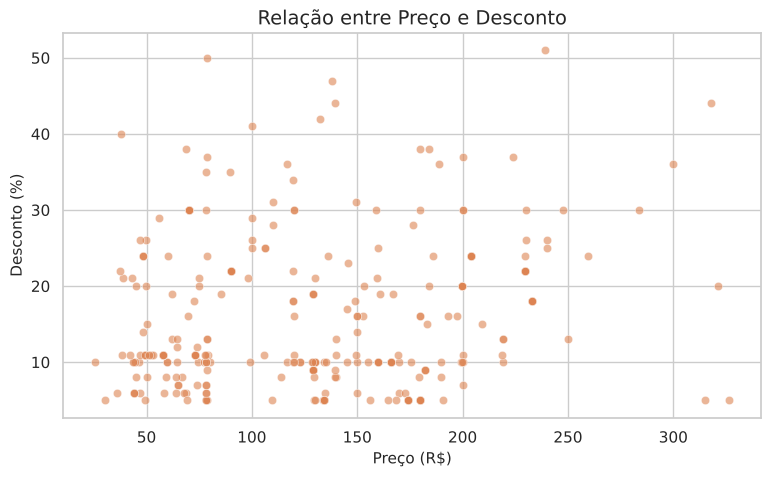

In [7]:
plt.figure()
sns.scatterplot(data=df, x="Preço", y="Desconto", alpha=0.6, color="#DD8452")

plt.title("Relação entre Preço e Desconto")
plt.xlabel("Preço (R$)")
plt.ylabel("Desconto (%)")
plt.show()

**Leitura:** os pontos ficam bem espalhados, sem um padrão forte (correlação de apenas ≈ 0,16). Ou seja, o preço do produto quase não determina o tamanho do desconto. Os pontos aparecem em "colunas verticais" porque muitos produtos compartilham o mesmo preço.

## 6. Mapa de calor — correlação entre variáveis

A **correlação** mede se duas variáveis "andam juntas":
- perto de **+1**: quando uma sobe, a outra também sobe;
- perto de **0**: não há relação;
- perto de **-1**: quando uma sobe, a outra desce.

Cores mais fortes indicam correlação mais forte.

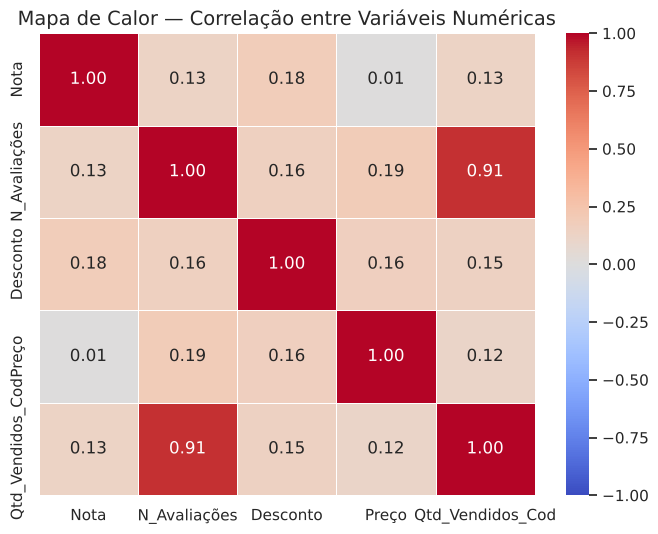

In [8]:
correlacao = df[colunas_principais].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)

plt.title("Mapa de Calor — Correlação entre Variáveis Numéricas")
plt.show()

**Leitura:** o destaque é a correlação muito forte (≈ 0,91) entre `N_Avaliações` e `Qtd_Vendidos_Cod`: produtos que vendem mais recebem mais avaliações. As demais variáveis têm correlações fracas entre si.

## 7. Gráfico de barras — marcas com mais produtos

Contamos quantos produtos cada marca tem e mostramos as 10 maiores.

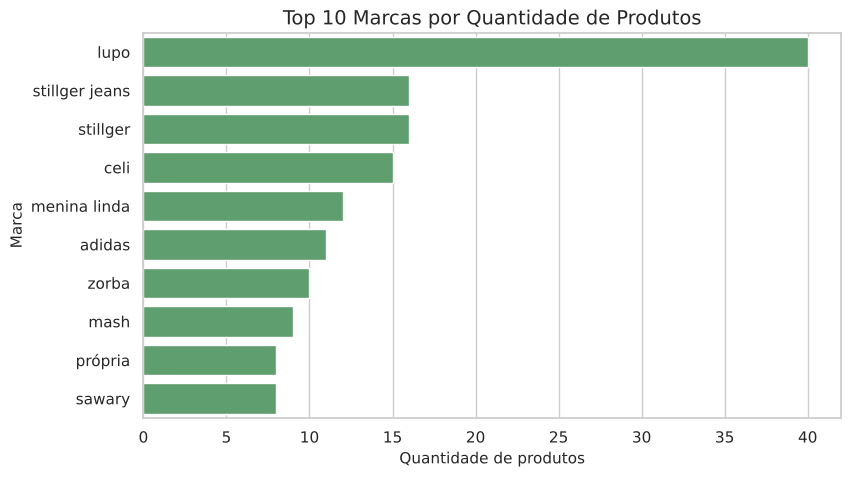

In [9]:
top_marcas = df["Marca"].value_counts().head(10)

plt.figure()
sns.barplot(x=top_marcas.values, y=top_marcas.index, color="#55A868")

plt.title("Top 10 Marcas por Quantidade de Produtos")
plt.xlabel("Quantidade de produtos")
plt.ylabel("Marca")
plt.show()

**Leitura:** a marca **Lupo** domina o catálogo, com bem mais produtos que as demais.

## 8. Gráfico de pizza — participação por gênero

A coluna `Gênero` tem várias categorias pequenas. Para o gráfico não ficar poluído, mantemos **Masculino** e **Feminino** e juntamos o restante em **Outros**.

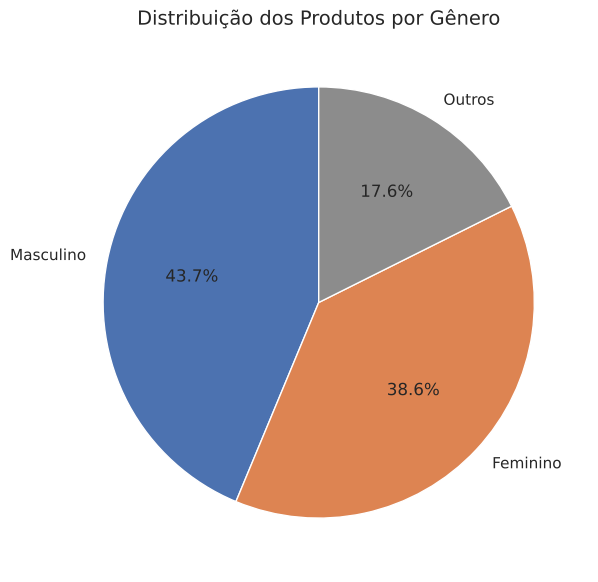

In [10]:
genero = df["Gênero"].where(df["Gênero"].isin(["Masculino", "Feminino"]), "Outros")
contagem_genero = genero.value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    contagem_genero.values,
    labels=contagem_genero.index,
    autopct="%1.1f%%",     # mostra a porcentagem em cada fatia
    startangle=90,
    colors=["#4C72B0", "#DD8452", "#8C8C8C"],
)
plt.title("Distribuição dos Produtos por Gênero")
plt.show()

**Leitura:** Masculino e Feminino somam a grande maioria do catálogo, com o masculino um pouco à frente.

## 9. Gráfico de densidade — preço por gênero

O gráfico de densidade é uma versão "suavizada" do histograma. Ele facilita **comparar grupos**: aqui, os preços de produtos masculinos e femininos.

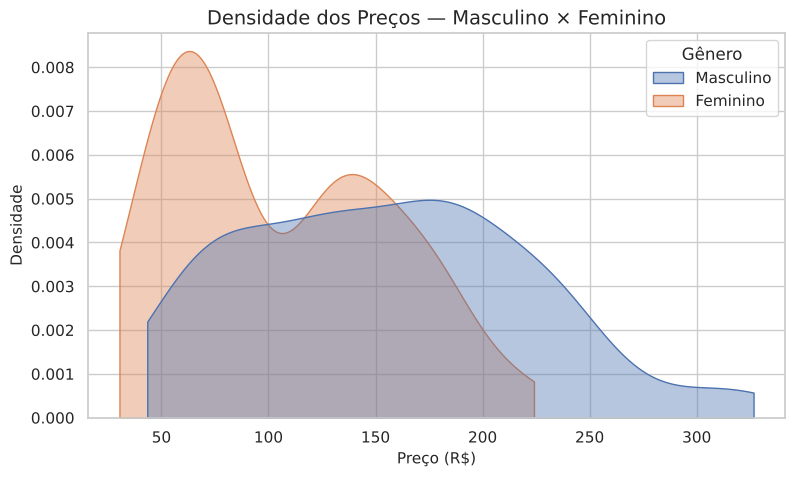

In [11]:
df_mf = df[df["Gênero"].isin(["Masculino", "Feminino"])]

plt.figure()
sns.kdeplot(data=df_mf, x="Preço", hue="Gênero", fill=True, common_norm=False, alpha=0.4, cut=0)

plt.title("Densidade dos Preços — Masculino × Feminino")
plt.xlabel("Preço (R$)")
plt.ylabel("Densidade")
plt.show()

In [12]:
# Para confirmar o que o gráfico mostra, comparamos o preço médio
df_mf.groupby("Gênero")["Preço"].mean().round(2)

Gênero
Feminino     105.32
Masculino    154.97
Name: Preço, dtype: float64

**Leitura:** produtos femininos se concentram em preços mais baixos (pico forte perto de R$ 60), enquanto os masculinos têm distribuição mais aberta e preço médio mais alto. Usamos `cut=0` para que a curva fique limitada ao intervalo real dos dados; sem esse parâmetro, a suavização faz a curva "invadir" preços abaixo de zero, que não existem na base.

## 10. Gráfico de regressão — avaliações × vendas

A linha de regressão resume a tendência entre duas variáveis. Como `N_Avaliações` e `Qtd_Vendidos_Cod` têm valores muito diferentes (de dezenas a milhares), usamos o **logaritmo (base 10)**, que "comprime" a escala e deixa a relação visível.

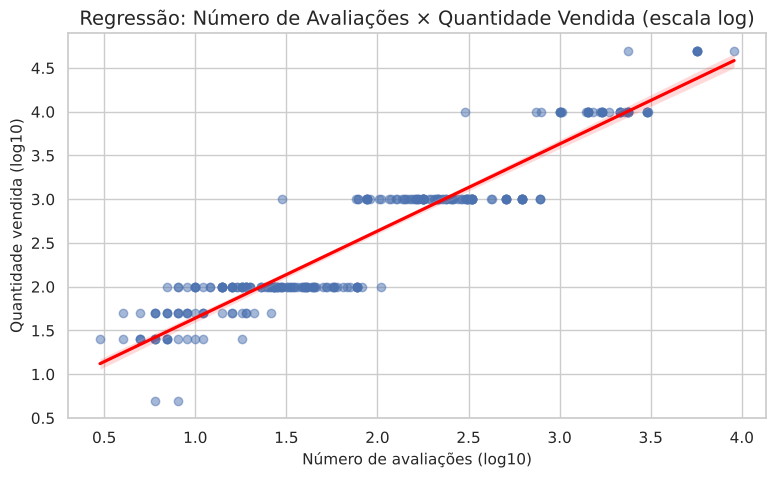

In [13]:
dados_reg = pd.DataFrame({
    "log_avaliacoes": np.log10(df["N_Avaliações"]),
    "log_vendas": np.log10(df["Qtd_Vendidos_Cod"]),
})

plt.figure()
sns.regplot(
    data=dados_reg, x="log_avaliacoes", y="log_vendas",
    scatter_kws={"alpha": 0.5}, line_kws={"color": "red"},
)

plt.title("Regressão: Número de Avaliações × Quantidade Vendida (escala log)")
plt.xlabel("Número de avaliações (log10)")
plt.ylabel("Quantidade vendida (log10)")
plt.show()

**Leitura:** a linha sobe claramente: produtos com mais avaliações vendem mais. Os pontos formam "faixas horizontais" porque a quantidade vendida no site é informada em faixas (+100, +1000, +10mil...), não como número exato. Isso é uma **associação** (não prova que avaliações causam vendas; produtos que vendem mais naturalmente acumulam mais avaliações).

## 11. Conclusões para o cliente

1. **Preços:** a maioria dos produtos fica entre R$ 50 e R$ 200.
2. **Descontos:** quase não dependem do preço, o que indica que a política de desconto não é proporcional ao valor do produto.
3. **Vendas e avaliações:** são fortemente associadas. Estimular avaliações pode ser uma boa estratégia para quem quer vender mais.
4. **Catálogo:** concentrado em poucas marcas (destaque para Lupo) e em produtos masculinos e femininos.
5. **Preço por gênero:** produtos masculinos têm preço médio maior que os femininos.